# 04 · Hypotheses, experiments, and decisions

A hypothesis test asks whether an observed result is unusually incompatible with a specified model. It does not prove a hypothesis, repair a poor study design, or decide whether an effect matters. Its value comes from connecting an explicit question to a calibrated decision rule.

```mermaid
flowchart LR
    A[Define effect and study design] --> B[State null and alternative]
    B --> C[Choose statistic and error rate]
    C --> D[Obtain null distribution]
    D --> E[Compare observed statistic]
    E --> F[Report effect, uncertainty, and limits]
```

**Learning route:** claim → hypotheses → statistic → null distribution → decision → interpretation. Prerequisites: [probability models](../03_Probability_Models/03_Probability_Models.md).

## 1. Translate an everyday claim into a parameter

A print shop wants to know whether a new preparation procedure changes job completion time. Let $\Delta=\mu_{\mathrm{new}}-\mu_{\mathrm{standard}}$, measured in minutes. The common two-sided hypotheses are

$$H_0:\Delta=0,\qquad H_1:\Delta\ne0.$$

The **null hypothesis** is the reference claim being tested; the **alternative** describes the departures the test is intended to detect. A null need not mean zero: we can test a target mean of 10 minutes or a difference of 2 minutes. The null is about a population parameter or data-generating process, not whether sample means happen to be exactly equal.

For a planned directional question, $H_0:\Delta\ge0$ versus $H_1:\Delta<0$ asks whether the new method reduces the mean. A typical one-sided calculation uses the boundary $\Delta=0$. Choose direction before examining the outcomes. A method can also be slower; a one-sided test for improvement does not provide an equivalent test for deterioration.

## 2. Study design comes before the test

If staff choose which jobs receive the new procedure, difficult jobs may be concentrated in one group. The procedure and job difficulty are then entangled. A test can detect a difference without identifying its cause.

Random assignment of eligible jobs makes the assignment mechanism known and balances other characteristics in expectation. Blocking by job size can improve precision when size strongly affects completion time. If one worker completes many jobs, those times may be correlated; the analysis must respect that clustering. The smallest experimental unit that receives an independently assigned treatment determines the effective replication.

Plan the primary outcome, contrast, sample size, significance level, treatment of exclusions, and handling of missing values before seeing results. Exploratory plots and hypotheses remain useful, but a hypothesis suggested by the same observations has already benefited from selection. Confirm it with new evidence or an analysis that accounts for that selection.

## 3. A test statistic compresses the relevant discrepancy

A **test statistic** is a numerical function of the data used to order evidence against $H_0$. For mean differences, the raw difference $T=\bar X_{\mathrm{new}}-\bar X_{\mathrm{standard}}$ is intuitive. A standardized statistic divides this difference by an estimated standard error, so a difference is judged relative to its noise.

The **null distribution** describes how the statistic would vary under the null and the study's sampling or assignment mechanism. It is not usually the histogram of individual observations. Two groups may have widely scattered individuals but precisely estimated averages if the samples are large and independent.

Under a symmetric two-sided test, large positive and large negative values count against a zero-effect null. We can order them by $|T|$. For a one-sided improvement test with this sign convention, more negative $T$ is more extreme.

## 4. An exact randomization example

Suppose six distinct jobs were randomly assigned, three to each procedure. The invented observed times are:

| Procedure | Completion times (minutes) | Mean |
|---|---|---:|
| Standard | 7, 8, 9 | 8 |
| New | 4, 5, 6 | 5 |

The observed statistic is $T=5-8=-3$ minutes. For this small example, consider the **sharp null**: changing the assigned procedure would change none of the six jobs' outcomes. Under that null, the six times are fixed and each of the $\binom63=20$ allocations of three jobs to the new group is equally probable.

For each allocation, compute new mean minus standard mean. Only two allocations have $|T|\ge3$: the observed complete separation and the reversed separation. The exact two-sided randomization p-value is therefore $2/20=0.10$.

![Every possible randomized assignment under the sharp null](figure/randomization.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '04_Hypothesis_Testing' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


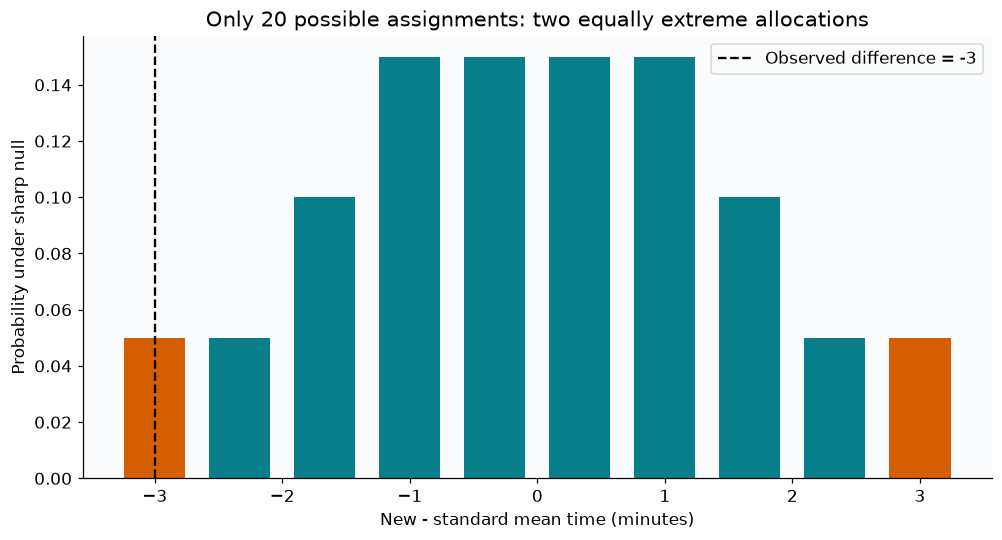

Exact two-sided p = 2/20 = 0.10


In [2]:
from itertools import combinations
standard = np.array([7,8,9])
new = np.array([4,5,6])
pooled = np.r_[new,standard]
observed = new.mean()-standard.mean()
null_differences = []
for chosen in combinations(range(6),3):
    mask = np.zeros(6,dtype=bool)
    mask[list(chosen)] = True
    null_differences.append(pooled[mask].mean()-pooled[~mask].mean())
null_differences = np.array(null_differences)
extreme = np.abs(null_differences)>=abs(observed)-1e-12
p_exact = extreme.mean()
assert len(null_differences)==20 and np.isclose(p_exact,.1)
values, counts = np.unique(np.round(null_differences,8),return_counts=True)
fig, ax = plt.subplots(layout="constrained")
ax.bar(values,counts/20,width=.48,color=np.where(abs(values)>=3-1e-7,ORANGE,TEAL))
ax.axvline(observed,ls="--",color="black",label=f"Observed difference = {observed:g}")
ax.set(xlabel="New - standard mean time (minutes)",ylabel="Probability under sharp null",
       title="Only 20 possible assignments: two equally extreme allocations")
ax.legend()
save_figure(fig,"randomization")
print(f"Exact two-sided p = {extreme.sum()}/20 = {p_exact:.2f}")

This is a deliberately instructive result: all three new-procedure jobs finished faster than all three standard-procedure jobs, yet the two-sided p-value exceeds 0.05. With only twenty possible assignments, strong-looking separation is not especially rare. More fundamentally, the calculation addresses the stated sharp null and random assignment. Arbitrarily permuting observational data requires an exchangeability assumption; equality of population means alone does not guarantee it when distributions differ.

## 5. Decisions and their possible errors

Choose a **significance level** $\alpha$, such as 0.05, before the analysis. A valid level-$\alpha$ test has probability at most $\alpha$ of rejection when the null is true, under its assumptions. Exact discrete tests may have an actual rejection rate below $\alpha$ because only certain p-values are attainable.

| Reality | Fail to reject $H_0$ | Reject $H_0$ |
|---|---|---|
| Null is true | Correct nonrejection | Type I error, false positive |
| Specified alternative is true | Type II error, false negative | Correct detection |

The Type II error probability $\beta$ depends on a particular alternative, sample size, variability, and test. **Power** is $1-\beta$. It is not a fixed property of a technique irrespective of the study. [Chapter 9](../09_Power_and_Power_Analysis/09_Power_and_Power_Analysis.md) develops power for planning data collection.

For the six-job example at $\alpha=0.05$, we fail to reject the sharp null. We can still report the observed difference of $-3$ minutes and explain that the design provides limited resolution. The threshold does not erase the data or make the procedures equivalent.

## 6. Why nonrejection is not equality

A study can fail to reject because the effect is absent, because it is small, or because uncertainty is large. These possibilities are not distinguished by a large p-value alone. The interval estimate provides useful context: an interval ranging from substantial benefit to substantial harm leaves both possibilities unresolved.

To support **practical equivalence**, define acceptable limits $[-m,m]$ before analysis and use a method designed to assess them. For example, if differences smaller than one minute are negligible, an appropriately calibrated interval contained within $[-1,1]$ can support equivalence. Merely obtaining $p>0.05$ for a zero-difference test cannot.

Likewise, rejecting $\Delta=0$ does not establish a useful improvement. A precisely estimated reduction of 0.01 minutes may be operationally irrelevant. Statistical decisions and practical decisions depend on different inputs: the latter also use costs, benefits, constraints, and meaningful effect sizes.

## 7. Repetition explains calibration

The notebook simulates many studies with a known measurement SD and a normal mean test. When the true shift is zero, the rejection fraction is near the chosen $\alpha$. When the shift increases, rejection becomes more frequent. Individual studies still vary: a correct procedure can yield a false positive, and a real effect can be missed.

![Decision rates across true effect sizes](figure/decision_rates.png)

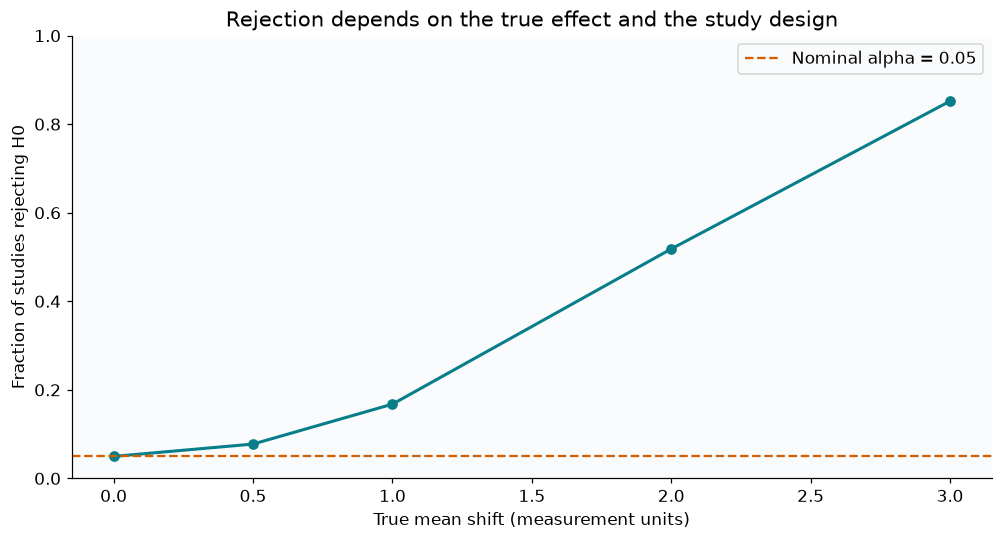

,true_shift,rejection_fraction
0,0.0,0.049583
1,0.5,0.077417
2,1.0,0.167583
3,2.0,0.518167
4,3.0,0.851917


In [3]:
rng = np.random.default_rng(404)
alpha, n, sigma, reps = .05, 25, 5, 12000
shifts = np.array([0,.5,1,2,3])
rejection_rates = []
for shift in shifts:
    # Equivalent to simulating n iid normal measurements and taking their mean.
    means = rng.normal(shift,sigma/np.sqrt(n),reps)
    p_values = 2*stats.norm.sf(np.abs(means/(sigma/np.sqrt(n))))
    rejection_rates.append(np.mean(p_values<=alpha))
fig, ax = plt.subplots(layout="constrained")
ax.plot(shifts,rejection_rates,"o-",lw=2)
ax.axhline(alpha,ls="--",color=ORANGE,label="Nominal alpha = 0.05")
ax.set(xlabel="True mean shift (measurement units)",ylabel="Fraction of studies rejecting H0",
       ylim=(0,1),title="Rejection depends on the true effect and the study design")
ax.legend()
save_figure(fig,"decision_rates")
display(pd.DataFrame({"true_shift":shifts,"rejection_fraction":rejection_rates}))

This simulation tests a zero mean using a known SD to keep the null distribution simple. It does not justify substituting a guessed SD into a real z-test. The t-test handles an estimated SD in [Chapter 8](../08_T-test_for_Testing_the_Differences/08_T-test_for_Testing_the_Differences.md).

## 8. Practice

1. A manufacturer asks whether a mean screw length equals 30 mm. Write a two-sided null and alternative. Does the null refer to the observed sample mean?
2. In a randomized experiment with two units per group, how many assignments are possible? Under an absolute mean-difference ordering and distinct maximally separated outcomes, what is the smallest attainable two-sided p-value?
3. A test returns $p=0.12$. Is there a 12% probability that the null is true? Does it establish no effect?
4. You test only for a decrease after discovering that the observed difference is negative. What is wrong with this plan?
5. A study's 95% interval for an effect is $[-8,7]$ minutes. Would it support equivalence within one minute?

## 9. Worked answers

1. $H_0:\mu=30$ versus $H_1:\mu\ne30$. These concern the population mean, not the observed sample mean.
2. $\binom42=6$ allocations. The most extreme assignment and its reverse give $2/6=1/3$. A two-sided 0.05 test cannot reject in this setting, even at complete separation.
3. Neither. The p-value is computed conditional on the null model; it is not a probability assigned to that model. Nonrejection leaves effects compatible with the uncertainty unresolved.
4. The direction was selected using the same noise the test evaluates. The nominal one-sided error rate no longer describes the full selection-and-testing procedure.
5. No. The interval allows effects much larger than the proposed equivalence margin. More precision, not relabeling the p-value, is needed.

In [4]:
from math import comb
assert comb(4,2)==6
print("Smallest two-sided p-value in practice 2:",2/comb(4,2))

Smallest two-sided p-value in practice 2: 0.3333333333333333


## References and next step

Reading connection: Starmer (2026), Chapter 4, [SQ](../Reference.md#sq-statquest). The exact assignment experiment is original. See [SciPy permutation-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) for null hypotheses and resampling conventions, and [the ASA statement](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf) for interpretation principles.

Next: [05 · P-values and confidence intervals](../05_P-Values_for_Confidence_Quantification/05_P-Values_for_Confidence_Quantification.md).